<a href="https://colab.research.google.com/github/allmargo/data_analyst/blob/main/ab_test_onboarding_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Оценка A/B-теста конверсии в первый депозит: кейс финтех-приложения

### Бизнес-контекст:
Финтех-приложение тестирует новый экран онбординга.
Ключевая метрика — конверсия в первый депозит. Историческая (базовая) конверсия старого экрана составляет 12%.

Прошла первая неделя теста. Продуктовая команда просит дать промежуточный ответ: можно ли уже сейчас катить новый экран на 100% пользователей или нужно подождать?

n = 1200 — количество новых пользователей за первую неделю (размер выборки).

q = 154 — количество пользователей, сделавших первый депозит.
Наблюдаемая конверсия = 154 / 1200 = 12.83%.

mu = 0.12 — вероятность успеха при справедливости нулевой гипотезы.

alpha = 0.05 — уровень статистической значимости.

H0: Конверсия не выросла (осталась на уровне 12% или ниже). Новый экран не работает.

H1: Конверсия выросла. Новый экран работает лучше.

Шаги анализа:

1. Построение распределения H0 и расчет критической границы.

2. Расчет одностороннего и двустороннего p-value.

3. Построение 95% доверительного интервала.

4. Оценка ошибки I рода, расчет статистической мощности и MDE.

5. Построение кривой мощности для определения целевого размера выборки.

6. Синтез результатов и бизнес-решение.

In [6]:
import numpy
import matplotlib.pyplot as pyplot
from scipy.stats import binom

In [35]:
n = 1200
mu = 0.12
q = 154
alpha = 0.05

binom_h0 = binom(n=1200, p=0.12) # создаём объект-распределение

Расчёт критического значения при известных n, mu, alpha.

In [24]:
def make_binom_criterion(n, mu, alpha=0.05):
  '''
  n: кол-во повторений в эксперименте
  mu: вероятность успеха при справедливости нулевой гипотезы
  alpha: уровень значимости критерия
  '''

  binom_h0 = binom(n=n, p=mu) # то, как в случае справедливости нулевой гипротезы выглядит распределение
  q = binom_h0.ppf(1 - alpha) # квантиль
  return q + 1 # граница критической области

print(make_binom_criterion(1200, mu=0.12, alpha=0.05))

164.0


### Построим график распределения в случае, если нулевая гипотеза верна.

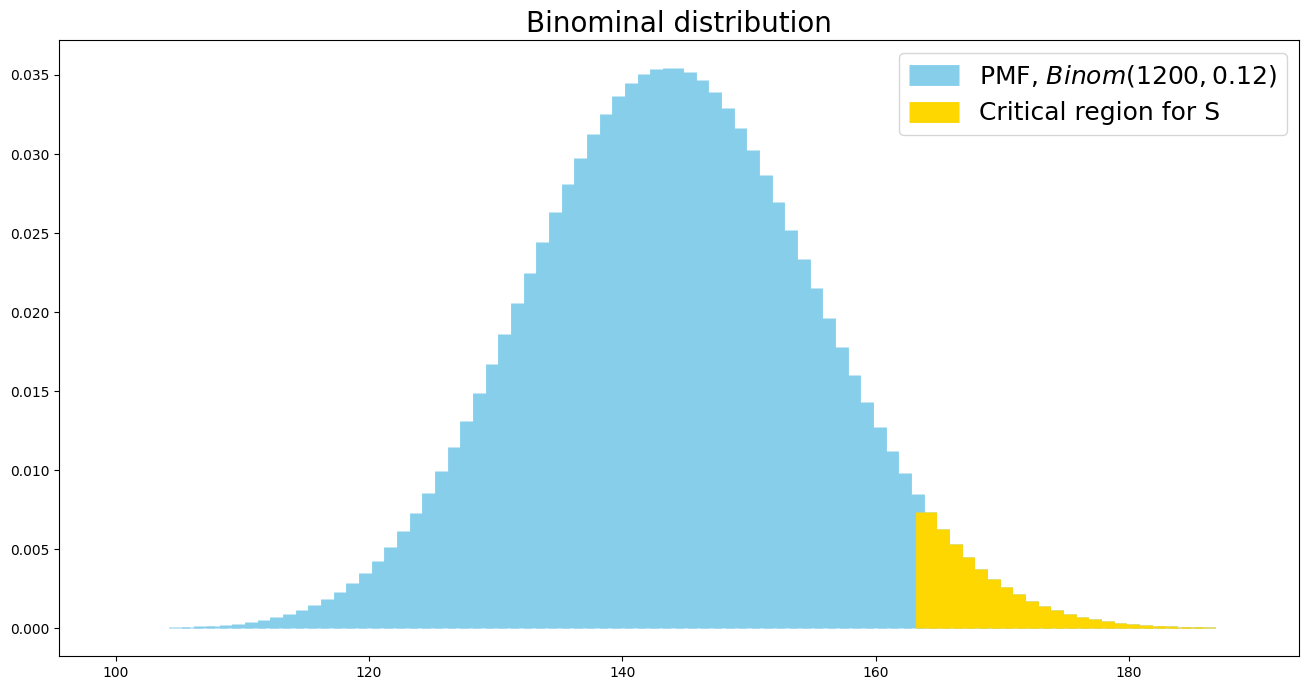

In [22]:
# ось x
x_grid = numpy.arange(100, 190)

# высоты столбцов на графике
probs = binom_h0.pmf(x_grid)

pyplot.figure(figsize=(16, 8))

pyplot.vlines(x_grid, 0, probs, linewidth=15.0, color='skyblue', label='PMF, $Binom(1200, 0.12)$')

# находим границу критической области
crit_value = (make_binom_criterion(1200, mu=0.12, alpha=0.05))
# массив логических значений
crit_reg = x_grid >= crit_value

pyplot.vlines(x_grid[crit_reg], 0, probs[crit_reg], linewidth=15.0, color='gold', label='Critical region for S')

pyplot.title('Binominal distribution', fontsize=20)
pyplot.legend(fontsize=18)
pyplot.show()

In [26]:
crit_val = make_binom_criterion(n=1200, mu=0.12, alpha=0.05)

if q >= crit_val:
    print(f'if statistics q ({q}) >= critical value ({crit_val}), then reject H0')
else:
    print(f'if statistics q ({q}) < critical value ({crit_val}), then DO NOT reject H0')

if statistics q (154) < critical value (164.0), then DO NOT reject H0


Вывод по критической области:
Наше фактическое наблюдение (154 депозита) меньше критической границы (164). Следовательно, результат не попадает в критическую область. Мы не можем отвергнуть нулевую гипотезу. Наблюдаемый рост конверсии с 12% до 12.83% находится в пределах случайных статистических колебаний. Эффект нового экрана не доказан.

Напишем функцию для нахождения P-value. **P-value** - вероятность получить такие же или более экстремальные результаты в данных, если нулевая гипотеза (H₀) верна.

In [32]:
def pvalue_binom(n, mu, q):
  '''
  n: кол-во повторений в эксперименте
  mu: вероятность успеха при справедливости нулевой гипотезы
  q: кол-во успехов в эксперименте
  '''
  binom_h0 = binom(n=n, p=mu)
  return 1 - binom_h0.cdf(q - 1)


if pvalue_binom(n, mu, q) <= 0.05:
    print(f'p-value = {pvalue_binom(n, mu, q):.4f} <= 0.05 (alpha), then reject H0')
else:
    print(f'p-value = {pvalue_binom(n, mu, q):.4f} > 0.05 (alpha), then DO NOT reject H0')

p-value = 0.1984 > 0.05 (alpha), then DO NOT reject H0


### Интерпретация p-value:

Полученное p-value составляет 0.1984. Это означает, что если бы новый экран не давал никакого эффекта (истинная конверсия осталась бы 12%), то вероятность случайно увидеть 154 депозита (или больше) из 1200 пользователей составляет почти 20%.

Поскольку 19.84% > 5% (нашего уровня значимости alpha), мы не отвергаем нулевую гипотезу. Наблюдаемый рост конверсии с 12% до 12.83% — это статистический шум. Мы не можем утверждать, что новый экран работает лучше.

Поскольку биномиальное распределение несимметрично, напишем функцию two_sided_criterion_nonsym, которая вычисляет левую и правую границы для двустороннего критерия. Это понадобится нам на следующем шаге для расчета 95% ДИ.

In [42]:
def two_sided_criterion_nonsym(n, mu, alpha):
  binom_h0 = binom(n=n, p=mu)

  # правая граница критической области
  c2 = binom_h0.ppf(1 - alpha/2) + 1

  # левая граница критической области
  c1 = binom_h0.ppf(alpha/2) - 1

  return c1, c2

c1, c2 = two_sided_criterion_nonsym(n=1200, mu=0.12, alpha=0.05)
print(c1, c2)

121.0 167.0


Ещё одно подтверждение того, что мы не можем отвергнуть H0. Наш результат — абсолютно нормальное случайное колебание вокруг базовой конверсии 12%.

Отобразим критическую область на графике для двустороннего критерия



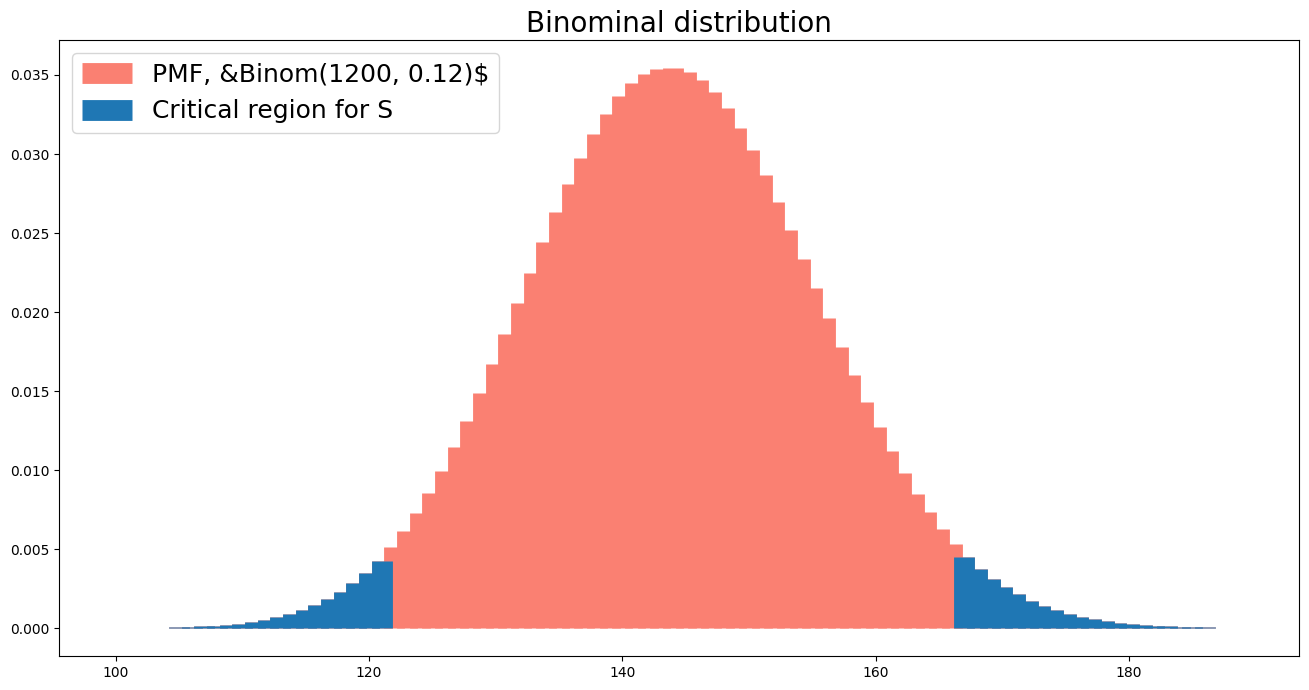

In [46]:
# ось x
x_grid = numpy.arange(100, 190)

binom_h0_nonsym = binom(n, mu)

pyplot.figure(figsize=(16, 8))

# считаем вероятности для каждой координаты х и строим для них столбцы
probs = binom_h0_nonsym.pmf(x_grid)
pyplot.vlines(x_grid, 0, probs, linewidth=15.0, color='salmon', label='PMF, &Binom(1200, 0.12)$')

# отображение критической области
crit_reg = (x_grid >= c2) | (x_grid <= c1)
pyplot.vlines(x_grid[crit_reg], 0, probs[crit_reg], linewidth=15.0, label='Critical region for S')

pyplot.title('Binominal distribution', fontsize=20)
pyplot.legend(fontsize=18, loc='upper left')
pyplot.show()

Функция для подсчёта pvalue для двусторонней альтернативы.

In [49]:
def pvalue_two_sided(n, q, mu):

  binom_h0 = binom(n=n, p=mu)

  # для левой части
  pvalue_left = binom_h0.cdf(q)
  # для правой части
  pvalue_right = 1 - binom_h0.cdf(q - 1)

  return 2 * min(pvalue_left, pvalue_right, 0.5)

print(pvalue_two_sided(n, q, mu))

0.39686691466119406


### Интерпретация двустороннего p-value:
Двусторонний p-value составляет 0.3968. Это означает, что вероятность получить наше наблюдение (154 депозита) или еще более экстремальное (в любую сторону) при условии, что истинная конверсия равна 12%, составляет почти 40%.

Мы хотим проверить: если реальный эффект нового экрана составляет, например, +1.5 п.п. (то есть конверсия выросла до 13.5%), сможем ли мы это заметить при n=1200? Посчитаем вероятность отвергнуть H0, когда её не нужно отвергать (False Positive Rate) и вероятность того, что мы правильно отвергнем H0 - мощность.

In [50]:
crit_val = make_binom_criterion(n=1200, mu=0.12, alpha=0.05)

# FPR (Ошибка I рода): вероятность ложной тревоги, если H0 верна (p=0.12)
fpr = 1 - binom(n, p=mu).cdf(crit_val - 1)

# Power (Мощность): вероятность правильно обнаружить эффект, если H1 верна (p=0.135)
power = 1 - binom(n, p=0.135).cdf(crit_val - 1)

print('False Positive Rate is {:.1%}'.format(fpr))
print('Power is {:.1%}'.format(power))

False Positive Rate is 4.4%
Power is 44.6%


### Почему тест не увидел эффект, даже если он есть?

FPR (Ошибка I рода) = 4.4%. Это вероятность ложной тревоги. Наша критическая граница настроена корректно, мы будем ошибочно отвергать H0 лишь в 4.4% случаев (близко к заданному alpha=0.05).

Power (Мощность) = 44.6%. Это способность теста обнаружить реальный эффект. Мы проверили сценарий, где конверсия реально выросла до 13.5% (прирост +1.5 п.п.). Мощность в 44.6% означает, что наш тест не способен надежно зафиксировать этот прирост. Даже если новый экран действительно работает на +1.5 п.п., мы с вероятностью более 55% не увидим этого из-за статистического шума при n=1200.

**Для надежного детектирования такого эффекта нам нужна мощность от 80%.**

### Функция нахождения мощности для произвольных параметров.

In [53]:
def get_stat_power(N, mu, mu_factual, alpha):
  '''Вычисляет стат мощность критерия для биномиального распределения

  N: кол-во бернуллиевских экспериментов (размер выборки)
  mu: вероятность успеха согласно нулевой гипотезе
  mu_factual: истинная вероятность успеха в эксперименте
  alpha: уровень значимости критерия
  '''
  binom_h0 = binom(n=N, p=mu)
  binom_factual = binom(n=N, p=mu_factual)

  # вычисляем критическое значение
  critical_value = binom_h0.ppf(1 - alpha) + 1

  return 1 - binom_factual.cdf(critical_value - 1)

In [58]:
get_stat_power(N=3000, mu=0.12, mu_factual=0.135, alpha=0.05)

np.float64(0.7956260971874783)

### Влияние размера выборки на мощность теста:
Как видно из расчетов, мощность критерия напрямую зависит от размера выборки.

При N=1200 мощность составляла всего 44.6%, поэтому мы не могли доверять результатам.

Если мы увеличим выборку до N=3000, мощность вырастет до 79.6%. Это значит, что при таком размере выборки мы сможем с 80% вероятностью заметить реальный рост конверсии на 1.5 п.п. (до 13.5%).

Вывод: Для принятия бизнес-решения нам необходимо добрать выборку как минимум до 3000 пользователей.

Чтобы найти точный необходимый размер выборки для мощности 80%, построим график зависимости мощности от количества бернуллиевских экспериментов.

<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_5678/4055042672.py:10: SyntaxWarning: invalid escape sequence '\m'
  pyplot.title('Power for $\mu = 0.135$', fontsize=18)


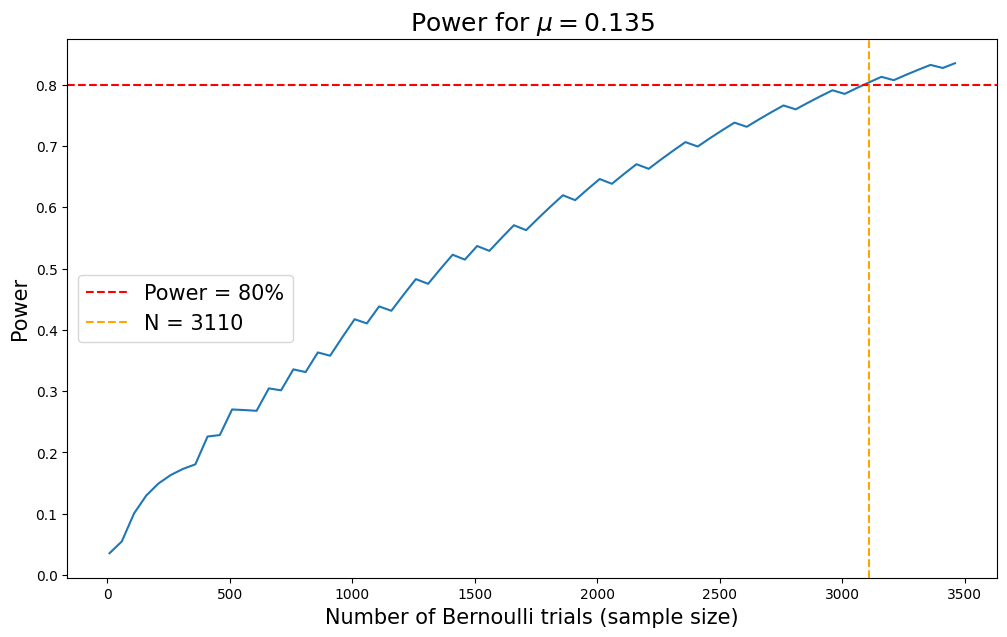

In [62]:
mu = 0.12
mu_factual = 0.135
alpha = 0.05

n_grid = numpy.arange(10, 3500, 50)

power = get_stat_power(n_grid, mu, mu_factual, alpha)

pyplot.figure(figsize=(12, 7))
pyplot.title('Power for $\mu = 0.135$', fontsize=18)
pyplot.xlabel('Number of Bernoulli trials (sample size)', fontsize=15)
pyplot.ylabel('Power', fontsize=15)

pyplot.plot(n_grid, power)
pyplot.axhline(0.8, ls='--', color='red', label='Power = 80%')

min_n = n_grid[power >= 0.8].min()
pyplot.axvline(min_n, ls='--', color='orange', label=f'N = {min_n}')

pyplot.legend(fontsize=15)
pyplot.show()

Точный размер выборки, чтобы с вероятностью 80% зафиксировать реальный рост конверсии на 1.5 п.п., 3110 пользователей.

Для детектирования меньшего эффекта нужен больший размер выборки. Посмотрим, как для фиксированного N меняется мощность для разных параметров μ.

<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_5678/2554627242.py:6: SyntaxWarning: invalid escape sequence '\m'
  pyplot.xlabel('$\mu$', fontsize=15)
/tmp/ipykernel_5678/2554627242.py:13: SyntaxWarning: invalid escape sequence '\m'
  pyplot.axvline(min_mu, ls='--', color='orange', label='$\mu$ = {:.2f}'.format(min_mu))


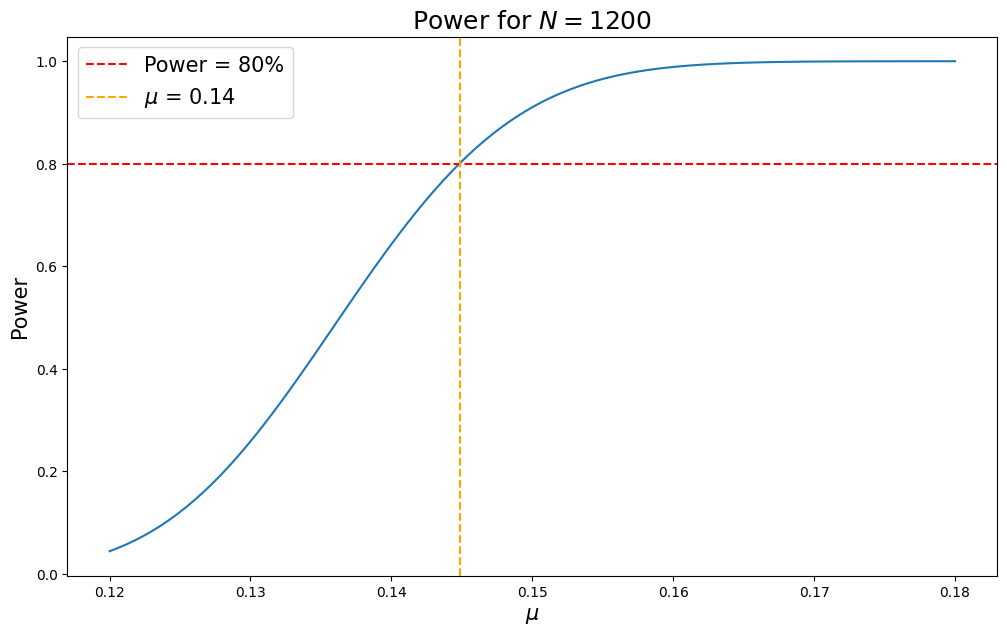

In [63]:
mu_grid = numpy.linspace(0.12, 0.18, 100)
power = get_stat_power(n, mu, mu_factual=mu_grid, alpha=0.05)

pyplot.figure(figsize=(12, 7))
pyplot.title('Power for $N = 1200$', fontsize=18)
pyplot.xlabel('$\mu$', fontsize=15)
pyplot.ylabel('Power', fontsize=15)

pyplot.plot(mu_grid, power)
pyplot.axhline(0.8, ls='--', color='red', label='Power = 80%')

min_mu = mu_grid[power >= 0.8].min()
pyplot.axvline(min_mu, ls='--', color='orange', label='$\mu$ = {:.2f}'.format(min_mu))

pyplot.legend(fontsize=15)
pyplot.show()

Определим MDE (Minimal Detectable Effect - минимальный детектируемый эффект) методом полного перебора.

In [64]:
def binom_mde_one_sided(n, mu, alpha=0.05, min_power=0.8):
  ''' Вычисляет MDE одностороннего критерия для проверки гипотезы mu = mu0

  n (int): размер выборки
  mu (float): вероятность успеха в нулевой гипотезе
  alpha (float): уровень значимости критерия
  min_power (float): желаемая мощность

  Возвращает: MDE (float)'''

  # сетка возможных значений для размера эффекта
  delta_grid = numpy.linspace(0, 1 - mu, 500)
  # массив значений мощности (power) для фиксированного размера выборки N и всех возможных величин эффекта
  power = get_stat_power(n, mu, mu + delta_grid, alpha=alpha)
  # отбирает из delta_grid размеры эффекта, дающие мощность ≥ min_power
  fit_delta = delta_grid[power >= min_power]

  return fit_delta[0]

In [66]:
binom_mde_one_sided(n, mu)

np.float64(0.026452905811623247)

### При выборке в 1200 человек мы сможем с вероятностью 80% заметить эффект, если конверсия увеличится до 14.64% и выше.

Построим двусторонний доверительный интервал (ДИ - множество допустимых значений истинного mu) при помощи полного перебора.

In [77]:
mu_grid = numpy.arange(0, 1.001, 0.001)
mu_no_rejection = []

for mu in mu_grid:
  c1, c2 = two_sided_criterion_nonsym(n, mu, alpha=0.10) # alpha= 0.05*2, т.к. строим двусторонний ДИ
  if q > c1 and q < c2:
    mu_no_rejection.append(mu)

print('95% confidence interval:  {} -- {}'.format(min(mu_no_rejection), max(mu_no_rejection)))

95% confidence interval:  0.113 -- 0.145


Доверительный интервал (0.113 -- 0.145) включает в себя базовую конверсию 12%, данные не противоречат тому, что новый экран не дал эффекта.



### Вывод:
1. Нет статистической значимости. Наблюдаемое количество депозитов (154) не дотягивает до критической границы (164). P-value составляет 0.1984, что значительно больше уровня значимости alpha=0.05. Наблюдаемый рост — это статистический шум.

2. Неточная оценка эффекта. 95% доверительный интервал (11.3% до 14.5%) включает в себя базовую конверсию 12%, а значит, мы не можем исключать, что новый экран вообще не изменил ситуацию (или даже ухудшил её).

3. Недостаточная мощность теста. При выборке в 1200 пользователей мощность нашего критерия для целевого эффекта (+1.5 п.п.) составляет всего 44.6%. MDE (минимальный детектируемый эффект) равен 2.64 п.п. — тест физически не способен увидеть такой маленький прирост, как +0.83 п.п., который мы получили.

### Бизнес-решение:
Отвергать нулевую гипотезу и катить новый экран на основе этих данных — значит рисковать и принимать решение на основе случайных колебаний. Мы продолжаем тест до накопления выборки минимум в 4400 пользователей, чтобы снизить MDE до ~1.2 п.п. и получить статистически надежный результат.